In [1]:
import matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

In [2]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [3]:
def applyCut(inputDataframe, cut):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    return cutDataframe

In [4]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

In [5]:
#observables = ['centrality','rho','jet_pt','jet_eta','jet_phi','jet_area','jet_neutral_fraction',\
#    'jet_leading_track_pt','jet_leading_track_y','jet_leading_track_phi','jet_leading_track_charge',\
#    'jet_subleading_track_pt','jet_subleading_track_y','jet_subleading_track_phi','jet_subleading_track_charge',\
#    'jet_leading_particle_pt','jet_leading_particle_y','jet_leading_particle_phi','jet_leading_particle_charge',\
#    'jet_subleading_particle_pt','jet_subleading_particle_y','jet_subleading_particle_phi','jet_subleading_particle_charge']
observables = ['centrality','rho','jet_pt','jet_area','jet_neutral_fraction','jet_leading_track_charge',\
    'jet_subleading_track_pt','jet_subleading_track_charge']

In [6]:
filename = '/home/ys668/project/other_output/rc/isobar2.root'
treename = 'jet_tree'

In [7]:
df = applyCut(getData(observables, filename, treename), 'jet_subleading_track_pt > 0 and jet_neutral_fraction < 0.9')

In [8]:
df

,centrality,rho,jet_pt,jet_area,jet_neutral_fraction,jet_leading_track_charge,jet_subleading_track_pt,jet_subleading_track_charge
0,15,48.981846,38.552380,0.498666,0.641543,1,1.421774,-1
1,15,48.981846,32.462891,0.528585,0.557585,-1,1.523050,1
2,15,48.981846,30.791693,0.448799,0.700939,1,1.646253,-1
3,15,48.981846,29.964878,0.478719,0.538627,-1,1.326742,-1
4,15,48.981846,28.165018,0.518612,0.390626,1,1.797630,-1
...,...,...,...,...,...,...,...,...
7479880,14,40.457436,18.574272,0.528585,0.695640,1,0.733231,1
7479881,14,40.457436,16.717098,0.339093,0.576297,1,1.023543,1
7479882,14,40.457436,16.452955,0.349066,0.553031,1,1.079626,-1
7479883,14,40.457436,15.828350,0.378986,0.572896,1,0.941080,-1


Text(0.5, 0, '$\\rho A$')

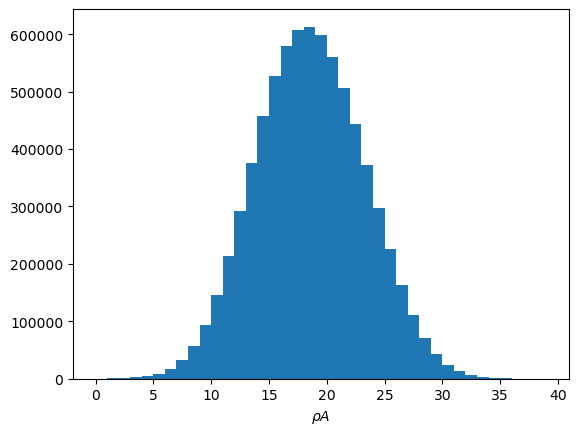

In [35]:
plt.hist(df['rho']*df['jet_area'], bins=np.arange(0,40))
plt.xlabel(r'$\rho A$')

In [9]:
df.eval('b = jet_leading_track_charge * jet_subleading_track_charge', inplace=True)
df.eval('jet_pt_sub = jet_pt - rho * jet_area', inplace=True)
df['w'] = np.ones(df.shape[0])

In [10]:
df_central = applyCut(df, 'centrality >= 11 and b!=0')
df_peripheral = applyCut(df, '0 <= centrality <= 5 and b!=0')

In [35]:
df_central_array = [ df_central[(df_central.jet_pt>15) & (df_central.jet_pt<20)],\
                       df_central[(df_central.jet_pt>20) & (df_central.jet_pt<25)],\
                       df_central[(df_central.jet_pt>25) & (df_central.jet_pt<30)],\
                       df_central[(df_central.jet_pt>30) & (df_central.jet_pt<40)] ]

In [36]:
df_peripheral_array = [ df_peripheral[(df_peripheral.jet_pt>15) & (df_peripheral.jet_pt<20)],\
                       df_peripheral[(df_peripheral.jet_pt>20) & (df_peripheral.jet_pt<25)],\
                       df_peripheral[(df_peripheral.jet_pt>25) & (df_peripheral.jet_pt<30)],\
                       df_peripheral[(df_peripheral.jet_pt>30) & (df_peripheral.jet_pt<40)] ]

In [37]:
rc_central_array = []
rc_err_central_array = []
for i in range(0, len(df_central_array)):
    rc_central_array.append(getRcAndErr(df_central_array[i], 'b')[0])
    rc_err_central_array.append(getRcAndErr(df_central_array[i], 'b')[1])

In [38]:
rc_peripheral_array = []
rc_err_peripheral_array = []
for i in range(0, len(df_peripheral_array)):
    rc_peripheral_array.append(getRcAndErr(df_peripheral_array[i], 'b')[0])
    rc_err_peripheral_array.append(getRcAndErr(df_peripheral_array[i], 'b')[1])

In [11]:
df_central_array = [ df_central[(df_central.jet_pt_sub>15) & (df_central.jet_pt_sub<20)],\
                       df_central[(df_central.jet_pt_sub>20) & (df_central.jet_pt_sub<25)],\
                       df_central[(df_central.jet_pt_sub>25) & (df_central.jet_pt_sub<30)],\
                       df_central[(df_central.jet_pt_sub>30) & (df_central.jet_pt_sub<40)] ]

In [12]:
df_peripheral_array = [ df_peripheral[(df_peripheral.jet_pt_sub>15) & (df_peripheral.jet_pt_sub<20)],\
                       df_peripheral[(df_peripheral.jet_pt_sub>20) & (df_peripheral.jet_pt_sub<25)],\
                       df_peripheral[(df_peripheral.jet_pt_sub>25) & (df_peripheral.jet_pt_sub<30)],\
                       df_peripheral[(df_peripheral.jet_pt_sub>30) & (df_peripheral.jet_pt_sub<40)] ]

In [13]:
rc_central_array = []
rc_err_central_array = []
for i in range(0, len(df_central_array)):
    rc_central_array.append(getRcAndErr(df_central_array[i], 'b')[0])
    rc_err_central_array.append(getRcAndErr(df_central_array[i], 'b')[1])

In [14]:
rc_peripheral_array = []
rc_err_peripheral_array = []
for i in range(0, len(df_peripheral_array)):
    rc_peripheral_array.append(getRcAndErr(df_peripheral_array[i], 'b')[0])
    rc_err_peripheral_array.append(getRcAndErr(df_peripheral_array[i], 'b')[1])

In [16]:
print(rc_central_array)
print(rc_err_central_array)
print(rc_peripheral_array)
print(rc_err_peripheral_array)

[-0.020801501139257474, -0.06776975884527373, -0.06246351430239346, -0.17355371900826447]
[0.0036602226108606475, 0.009359938807418434, 0.024114175649176627, 0.05168987588417304]
[-0.2542372881355932, -0.1896551724137931, -0.3, -0.42857142857142855]
[0.03981660077348412, 0.09116255449019844, 0.15083103128998357, 0.2414726442081476]


In [15]:
rc_pp_array = np.array([-0.3087933449476, -0.3049137767841851, -0.30877555891479036, -0.2980493793479744])
rc_err_pp_array = np.array([0.0013247772219597514, 0.002859432635262245, 0.005998971104851678, 0.011148521567582732])

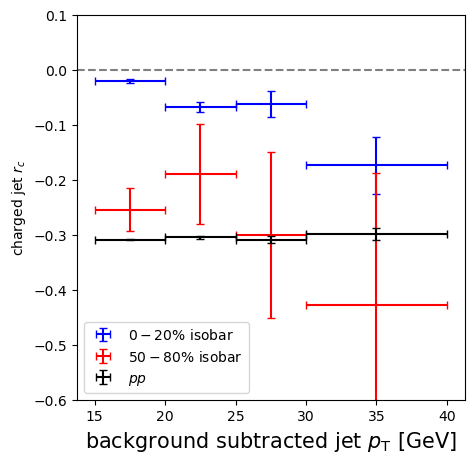

In [17]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], rc_central_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_central_array, capsize=3, color='b', ls='none', label='$0-20\%$ isobar')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_peripheral_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_peripheral_array, capsize=3, color='r', ls='none', label='$50-80\%$ isobar')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_pp_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_pp_array, capsize=3, color='k', ls='none', label='$pp$')
plt.xlabel('background subtracted jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='lower left')

In [19]:
df_central_hc = applyCut(df_central, 'jet_subleading_track_pt > 2')

In [20]:
df_central_hc_array = [ df_central_hc[(df_central_hc.jet_pt>15) & (df_central_hc.jet_pt<20)],\
                       df_central_hc[(df_central_hc.jet_pt>20) & (df_central_hc.jet_pt<25)],\
                       df_central_hc[(df_central_hc.jet_pt>25) & (df_central_hc.jet_pt<30)],\
                       df_central_hc[(df_central_hc.jet_pt>30) & (df_central_hc.jet_pt<40)] ]

In [21]:
rc_central_hc_array = []
rc_err_central_hc_array = []
for i in range(0, len(df_central_hc_array)):
    rc_central_hc_array.append(getRcAndErr(df_central_hc_array[i], 'b')[0])
    rc_err_central_hc_array.append(getRcAndErr(df_central_hc_array[i], 'b')[1])

In [22]:
print(rc_central_hc_array)
print(rc_err_central_hc_array)

[-0.036004645760743324, -0.052207226381550946, -0.04424045827869418, -0.04437251608145204]
[0.006554429011006827, 0.0049971181456628915, 0.004791756553047472, 0.004521680109783628]


In [24]:
rc_pp_hc_array = np.array([-0.329524369823958, -0.31518870414357353, -0.3132168214090661, -0.3042431537767078])
rc_err_pp_hc_array = np.array([0.0015878628958714723, 0.0031471074370218247, 0.006406830702165019, 0.011684976911908687])

Text(0.5, 1.0, '$p_{\\mathrm{T, lead}}, p_{\\mathrm{T, sublead}} > 2$ GeV')

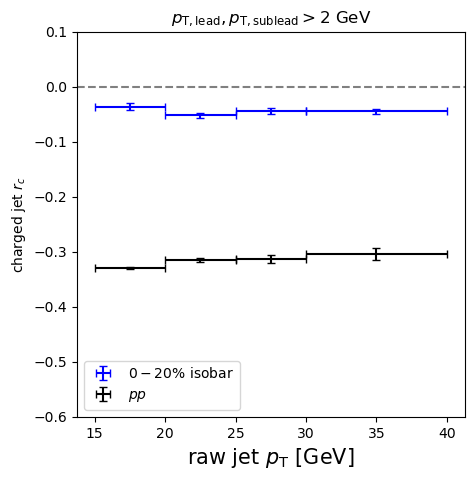

In [25]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], rc_central_hc_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_central_hc_array, capsize=3, color='b', ls='none', label='$0-20\%$ isobar')
#plt.errorbar([17.5, 22.5, 27.5, 35], rc_peripheral_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_peripheral_array, capsize=3, color='r', ls='none', label='$50-80\%$ isobar')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_pp_hc_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_pp_hc_array, capsize=3, color='k', ls='none', label='$pp$')
plt.xlabel('raw jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='lower left')
plt.title('$p_{\mathrm{T, lead}}, p_{\mathrm{T, sublead}} > 2$ GeV')

In [27]:
df_central_hc = applyCut(df_central, 'jet_subleading_track_pt > 2')

In [37]:
df_peripheral_hc = applyCut(df_peripheral, 'jet_subleading_track_pt > 2')

In [28]:
df_central_hc_array = [ df_central_hc[(df_central_hc.jet_pt_sub>15) & (df_central_hc.jet_pt_sub<20)],\
                       df_central_hc[(df_central_hc.jet_pt_sub>20) & (df_central_hc.jet_pt_sub<25)],\
                       df_central_hc[(df_central_hc.jet_pt_sub>25) & (df_central_hc.jet_pt_sub<30)],\
                       df_central_hc[(df_central_hc.jet_pt_sub>30) & (df_central_hc.jet_pt_sub<40)] ]

In [38]:
df_peripheral_hc_array = [ df_peripheral_hc[(df_peripheral_hc.jet_pt_sub>15) & (df_peripheral_hc.jet_pt_sub<20)],\
                       df_peripheral_hc[(df_peripheral_hc.jet_pt_sub>20) & (df_peripheral_hc.jet_pt_sub<25)],\
                       df_peripheral_hc[(df_peripheral_hc.jet_pt_sub>25) & (df_peripheral_hc.jet_pt_sub<30)],\
                       df_peripheral_hc[(df_peripheral_hc.jet_pt_sub>30) & (df_peripheral_hc.jet_pt_sub<40)] ]

In [29]:
rc_central_hc_array = []
rc_err_central_hc_array = []
for i in range(0, len(df_central_hc_array)):
    rc_central_hc_array.append(getRcAndErr(df_central_hc_array[i], 'b')[0])
    rc_err_central_hc_array.append(getRcAndErr(df_central_hc_array[i], 'b')[1])

In [29]:
rc_central_hc_array = []
rc_err_central_hc_array = []
for i in range(0, len(df_central_hc_array)):
    rc_central_hc_array.append(getRcAndErr(df_central_hc_array[i], 'b')[0])
    rc_err_central_hc_array.append(getRcAndErr(df_central_hc_array[i], 'b')[1])

Text(0.5, 1.0, '$p_{\\mathrm{T, lead}}, p_{\\mathrm{T, sublead}} > 2$ GeV')

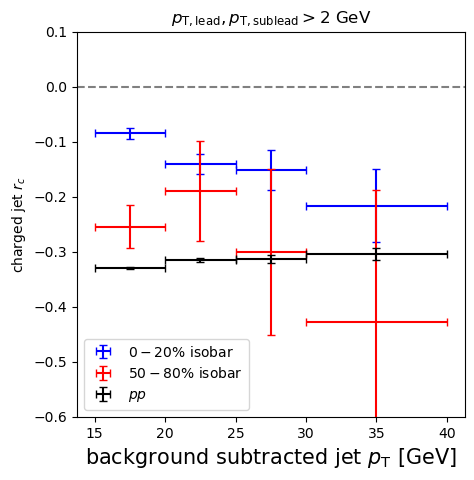

In [41]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], rc_central_hc_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_central_hc_array, capsize=3, color='b', ls='none', label='$0-20\%$ isobar')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_peripheral_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_peripheral_array, capsize=3, color='r', ls='none', label='$50-80\%$ isobar')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_pp_hc_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_pp_hc_array, capsize=3, color='k', ls='none', label='$pp$')
plt.xlabel('background subtracted jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='lower left')
plt.title('$p_{\mathrm{T, lead}}, p_{\mathrm{T, sublead}} > 2$ GeV')

In [47]:
observables1 = ['pt','b','pt2']

In [49]:
file = uproot.open('/home/ys668/project/other_output/rc/data0613_chargedrc.root')
tree = file["ResultTree"].arrays(observables1, library='np')
#array = []
#for observable in observables1:
#    array.append(np.concatenate(tree[observable]))
df_pp = pd.DataFrame(np.transpose(np.array((np.concatenate(tree['pt']),np.concatenate(tree['b']),np.concatenate(tree['pt2'])))),\
                     columns=["pts","bs","pt2s"])
df_pp = applyCut(df_pp, 'pts>15 and bs!= -9')

In [50]:
df_pp['w'] = np.ones(df_pp.shape[0])
df_pp['ws'] = np.ones(df_pp.shape[0])

In [51]:
df_pp_array = [ df_pp[(df_pp.pts>15) & (df_pp.pts<20)],\
                       df_pp[(df_pp.pts>20) & (df_pp.pts<25)],\
                       df_pp[(df_pp.pts>25) & (df_pp.pts<30)],\
                       df_pp[(df_pp.pts>30) & (df_pp.pts<40)] ]

In [52]:
rc_pp_array = []
rc_err_pp_array = []
for i in range(0, len(df_pp_array)):
    rc_pp_array.append(getRcAndErr(df_pp_array[i], 'bs')[0])
    rc_err_pp_array.append(getRcAndErr(df_pp_array[i], 'bs')[1])

In [54]:
df_pp_hc = applyCut(df_pp, 'pt2s > 2')

In [55]:
df_pp_hc_array = [ df_pp_hc[(df_pp_hc.pts>15) & (df_pp_hc.pts<20)],\
                       df_pp_hc[(df_pp_hc.pts>20) & (df_pp_hc.pts<25)],\
                       df_pp_hc[(df_pp_hc.pts>25) & (df_pp_hc.pts<30)],\
                       df_pp_hc[(df_pp_hc.pts>30) & (df_pp_hc.pts<40)] ]

In [58]:
rc_pp_hc_array = []
rc_err_pp_hc_array = []
for i in range(0, len(df_pp_hc_array)):
    rc_pp_hc_array.append(getRcAndErr(df_pp_hc_array[i], 'bs')[0])
    rc_err_pp_hc_array.append(getRcAndErr(df_pp_hc_array[i], 'bs')[1])

In [53]:
print(rc_pp_array)
print(rc_err_pp_array)

[-0.3087933449476, -0.3049137767841851, -0.30877555891479036, -0.2980493793479744]
[0.0013247772219597514, 0.002859432635262245, 0.005998971104851678, 0.011148521567582732]


In [59]:
print(rc_pp_hc_array)
print(rc_err_pp_hc_array)

[-0.329524369823958, -0.31518870414357353, -0.3132168214090661, -0.3042431537767078]
[0.0015878628958714723, 0.0031471074370218247, 0.006406830702165019, 0.011684976911908687]
